## Setup

### Import

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import MinMaxScaler

from autogluon.tabular import TabularDataset, TabularPredictor


In [2]:
df = pd.read_csv("data/AB_NYC_2019.csv")

### Preprocessing

In [3]:
# impute n/a for null names
df["name"] = df["name"].fillna("No Name")

# drop rows in df with null last review
df = df.drop(columns=["last_review","host_name", "id", "host_id"])
df.drop(df[df["reviews_per_month"].isna()].index, inplace=True)


In [4]:
df = df[df['availability_365'] >= 52]
df = df[df['price'] <= 1000]
df = df[df['price'] >= 15]


In [5]:
categorical_columns = ['neighbourhood_group', 'room_type', 'neighbourhood']
numerical_columns = ['latitude', 'longitude', 'minimum_nights',
                     'number_of_reviews', 'reviews_per_month', 'calculated_host_listings_count',
                     'availability_365']

In [6]:
train_data = df.sample(frac=0.8, random_state=42)
test_data = df.drop(train_data.index)


In [7]:
# apply minmaxscaler
scaler = MinMaxScaler()
train_data[numerical_columns] = scaler.fit_transform(train_data[numerical_columns])
test_data[numerical_columns] = scaler.transform(test_data[numerical_columns])


#### Data Preprocessing

Before training the models, the dataset was cleaned and preprocessed to improve data quality and prepare the features for machine learning. Missing values in the name column were addressed by filling it with "No name", and listings were filtered based on price and availability to focus the analysis on a more realistic subset of properties that were regularly listed. Numerical features were scaled using MinMaxScaler, while categorical variables such as neighborhood and room type are handled through AutoGluon's built-in preprocessing.

## AutoGluon Tasks

### Model Training

In [8]:
predictor = TabularPredictor(
    label="price",
    problem_type="regression",
    eval_metric="mean_absolute_error",
    path="AutogluonModels/final_experiment"
).fit(
    train_data,
    presets="medium"
)

y_pred = predictor.predict(test_data.drop(columns=['price']))
print("Predictions: \n", y_pred)

Preset alias specified: 'medium' maps to 'medium_quality'.
Verbosity: 2 (Standard Logging)
=================== System Info ===================
AutoGluon Version:  1.6.3
Python Version:     3.11.17
Operating System:   Windows
Platform Machine:   AMD64
Platform Version:   10.0.26200
CPU Count:          8
Pytorch Version:    2.13.0+cpu
CUDA Version:       CUDA is not available
Memory Avail:       0.96 GB / 7.92 GB (12.1%)
Disk Space Avail:   18.49 GB / 236.34 GB (7.8%)
Presets specified: ['medium']
Using hyperparameters preset: hyperparameters='default'
Beginning AutoGluon training ...
AutoGluon will save models to "c:\Users\bekel\airbnb_Predictor\AutogluonModels\final_experiment"
Train Data Rows:    15704
Train Data Columns: 11
Label Column:       price
Problem Type:       regression
Preprocessing data...
Using Feature Generators to preprocess the data ...
Fitting AutoMLPipelineFeatureGenerator...
	Available Memory:                    979.89 MB
	Train Data (Original)  Memory Usage: 5.34 

Predictions: 
 3        151.511780
21       105.865540
23        90.802567
25        67.974220
29       183.429321
            ...    
48401     56.669495
48404     79.791702
48534     72.438103
48782    116.561501
48799     66.419289
Name: price, Length: 3926, dtype: float32


In [9]:
evaluation = predictor.evaluate(test_data)
print("Evaluation: \n", evaluation)
perf = predictor.evaluate_predictions(y_true=test_data['price'], y_pred=y_pred, auxiliary_metrics=True)




Caching the list of root modules, please wait!
(This will only be done once - type '%rehashx' to reset cache!)

Evaluation: 
 {'mean_absolute_error': -42.69731140136719, 'root_mean_squared_error': np.float64(-84.28613573724863), 'mean_squared_error': -7104.15283203125, 'r2': 0.5454967021942139, 'pearsonr': 0.7466616315232633, 'median_absolute_error': -21.59571075439453}


In [10]:
print(predictor.leaderboard(test_data, silent=True))

                 model  score_test  score_val          eval_metric  \
0  WeightedEnsemble_L2  -42.697311 -45.941200  mean_absolute_error   
1             CatBoost  -42.890785 -46.590824  mean_absolute_error   
2        ExtraTreesMSE  -45.372868 -49.171535  mean_absolute_error   
3           LightGBMXT  -46.164616 -49.353165  mean_absolute_error   
4             LightGBM  -46.264820 -48.815086  mean_absolute_error   
5      RandomForestMSE  -46.342072 -49.204170  mean_absolute_error   
6              XGBoost  -46.441528 -48.807568  mean_absolute_error   
7        LightGBMLarge  -46.558178 -49.567886  mean_absolute_error   
8       NeuralNetTorch  -48.559391 -53.273590  mean_absolute_error   
9      NeuralNetFastAI  -50.552006 -55.159344  mean_absolute_error   

   pred_time_test  pred_time_val    fit_time  pred_time_test_marginal  \
0        3.581322       0.733183  421.776872                 0.012489   
1        0.230594       0.039442  226.598697                 0.230594   
2        2

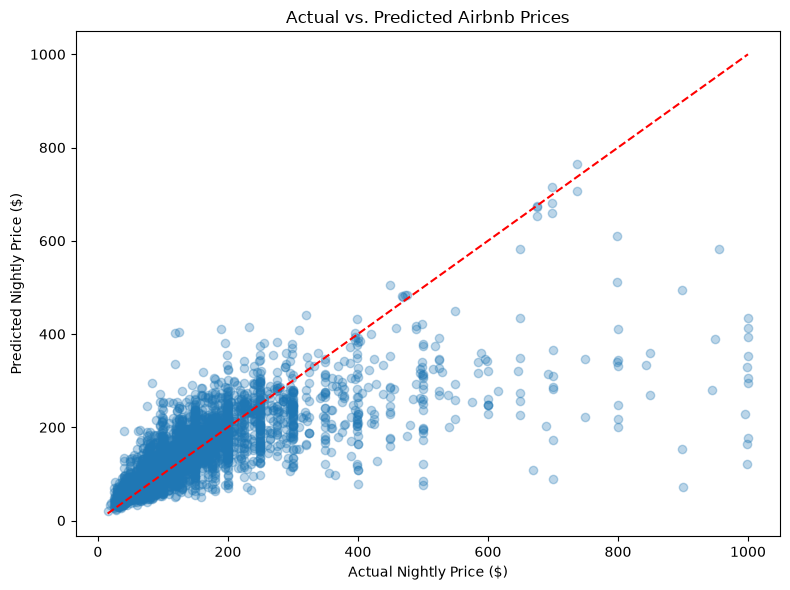

In [99]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.3)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    "r--"
)

plt.xlabel("Actual Nightly Price ($)")
plt.ylabel("Predicted Nightly Price ($)")
plt.title("Actual vs. Predicted Airbnb Prices")

plt.tight_layout()
plt.show()

#### Analysis

AutoGluon was used to train and compare several regression models, including LightGBM, CatBoost, XGBoost, Random Forest, Extra Trees, and neural networks implemented through PyTorch and FastAI. The goal was to identify which algorithms could best predict Airbnb nightly prices based on property characteristics, location, and listing information.

The weighted ensemble achieved the best overall performance by combining predictions from multiple models, while CatBoost was the strongest individual model. Although both neural-network models successfully trained, they did not outperform the strongest tree-based models.

### Feature Importance

In [11]:
importance = predictor.feature_importance(test_data)
print(importance)

Computing feature importance via permutation shuffling for 11 features using 3926 rows with 5 shuffle sets...
	221.42s	= Expected runtime (44.28s per shuffle set)
	56.64s	= Actual runtime (Completed 5 of 5 shuffle sets)


                                importance    stddev       p_value  n  \
room_type                        27.903966  0.373856  3.865740e-09  5   
name                             10.873280  0.338595  1.126940e-07  5   
longitude                         6.413420  0.337424  9.160660e-07  5   
minimum_nights                    5.881676  0.218803  2.293977e-07  5   
latitude                          3.204491  0.198558  1.759829e-06  5   
neighbourhood                     1.879408  0.122882  2.180597e-06  5   
availability_365                  1.522952  0.155393  1.282811e-05  5   
calculated_host_listings_count    1.454734  0.105171  3.255489e-06  5   
reviews_per_month                 1.438539  0.122051  6.158920e-06  5   
number_of_reviews                 1.402474  0.134142  9.921748e-06  5   
neighbourhood_group               1.071180  0.119741  1.842882e-05  5   

                                 p99_high    p99_low  
room_type                       28.673741  27.134190  
name         

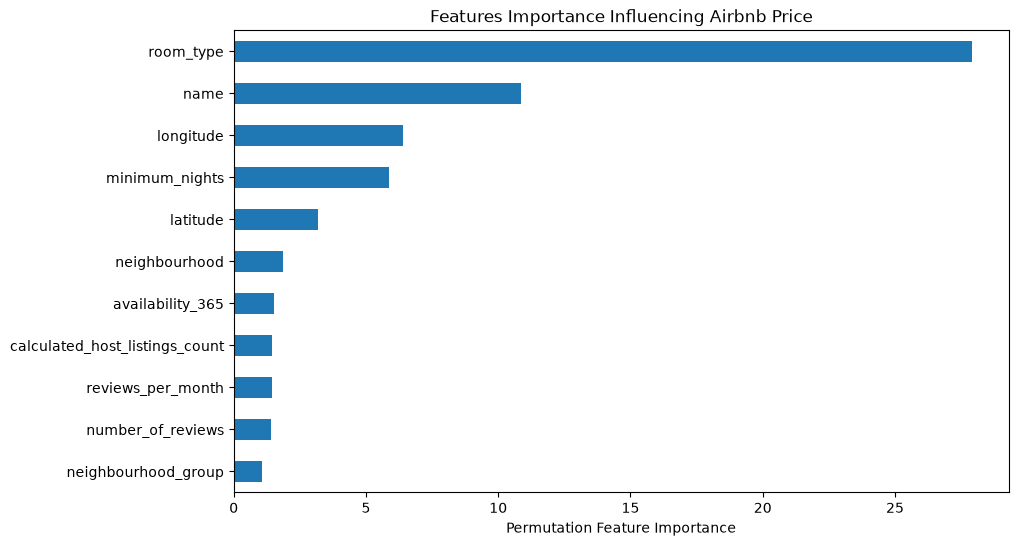

In [12]:
importance.head(15)['importance'].sort_values().plot(
    kind='barh',
    figsize=(10, 6),
    title='Features Importance Influencing Airbnb Price'
)

plt.xlabel('Permutation Feature Importance')
plt.show()

#### Feature Importance Analysis

Feature importance was evaluated using AutoGluon's permutation importance method, which measures how much prediction error increases when an individual feature is shuffled. These importance scores measure predictive usefulness rather than direct causal effects on price.

Room type was the most influential feature, with an importance score of approximately 27.90, followed by listing name at 10.87. Longitude (6.41), minimum nights (5.88), and latitude (3.20) were also among the most important features.

The importance of room type makes sense given the pricing differences between entire homes, private rooms, and shared rooms. Listing names were also highly informative, suggesting that descriptions contain useful information about property characteristics, amenities, and location. The geographic features further indicate that location contributes significantly to price predictions.

### Property Type Analysis

In [13]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

comparison = pd.DataFrame({
    "actual": test_data["price"],
    "predicted": y_pred,
    "room_type": df.loc[test_data.index, "room_type"]
})

comparison["absolute_error"] = abs(
    comparison["actual"] - comparison["predicted"]
)

room_analysis = (
    comparison.groupby("room_type")
    .apply(
        lambda group: pd.Series({
            "Count": len(group),
            "Avg_Price": group["actual"].mean(),
            "MAE": mean_absolute_error(
                group["actual"], group["predicted"]
            ),
            "RMSE": np.sqrt(mean_squared_error(
                group["actual"], group["predicted"]
            )),
            "R2": r2_score(
                group["actual"], group["predicted"]
            )
        }),
        include_groups=False
    )
    .sort_values("MAE", ascending=False)
)

room_analysis["norm_MAE"] = (
    room_analysis["MAE"] / room_analysis["Avg_Price"]
) * 100

In [14]:
overall_metrics = pd.DataFrame({
    "Count": [len(comparison)],
    "Avg_Price": [comparison["actual"].mean()],
    "MAE": [mean_absolute_error(
        comparison["actual"], comparison["predicted"]
    )],
    "RMSE": [np.sqrt(mean_squared_error(
        comparison["actual"], comparison["predicted"]
    ))],
    "R2": [r2_score(
        comparison["actual"], comparison["predicted"]
    )]
}, index=["All Types"])

overall_metrics["norm_MAE"] = (
    overall_metrics["MAE"] / overall_metrics["Avg_Price"]
) * 100

final_table = pd.concat([room_analysis, overall_metrics])
display(final_table.round(2))

,Count,Avg_Price,MAE,RMSE,R2,norm_MAE
Entire home/apt,1948.0,206.45,61.87,106.74,0.40,29.97
Private room,1878.0,86.52,24.12,54.24,0.42,27.88
Shared room,100.0,53.96,18.04,41.44,0.25,33.44
All Types,3926.0,145.20,42.70,84.29,0.55,29.41


#### Model Performance by Room Type

The original AutoGluon ensemble was also evaluated separately for entire homes, private rooms, and shared rooms to determine whether prediction accuracy varied across property types.

Entire homes had the highest average nightly price ($206.45) and largest MAE ($61.87). Private rooms had a lower average price of $86.52 and an MAE of $24.12, while shared rooms had an average price of $53.96 and an MAE of $18.04. After normalizing MAE by each room type's average price, the differences were less pronounced. Entire homes had a normalized MAE of 29.97%, compared with 27.88% for private rooms and 33.44% for shared rooms. This suggests that larger absolute errors for entire homes are partly associated with their higher prices. The shared-room results should be interpreted cautiously due to the limited amount of shared-room listings present in the test set.

## Optional task 1: Linear Regression vs AutoGluon

### Controlled AutoGluon (No Name)

In [15]:
drop_cols =["id", "name", "host_id", "host_name", "last_review"]

nn_train = train_data.drop(columns=drop_cols, errors="ignore")
nn_test = test_data.drop(columns=drop_cols, errors="ignore")

nn_predictor = TabularPredictor(
    label="price",
    problem_type="regression",
    eval_metric="mean_absolute_error",
    path="AutogluonModels/controlled_experiment"
).fit(
    train_data=nn_train,
    presets="medium"
)

Preset alias specified: 'medium' maps to 'medium_quality'.
Verbosity: 2 (Standard Logging)
=================== System Info ===================
AutoGluon Version:  1.6.3
Python Version:     3.11.17
Operating System:   Windows
Platform Machine:   AMD64
Platform Version:   10.0.26200
CPU Count:          8
Pytorch Version:    2.13.0+cpu
CUDA Version:       CUDA is not available
Memory Avail:       1.09 GB / 7.92 GB (13.7%)
Disk Space Avail:   18.28 GB / 236.34 GB (7.7%)
Presets specified: ['medium']
Using hyperparameters preset: hyperparameters='default'
Beginning AutoGluon training ...
AutoGluon will save models to "c:\Users\bekel\airbnb_Predictor\AutogluonModels\controlled_experiment"
Train Data Rows:    15704
Train Data Columns: 10
Label Column:       price
Problem Type:       regression
Preprocessing data...
Using Feature Generators to preprocess the data ...
Fitting AutoMLPipelineFeatureGenerator...
	Available Memory:                    1129.00 MB
	Train Data (Original)  Memory Usage:

In [74]:
nn_y_true = nn_test["price"]

nn_y_pred = nn_predictor.predict(nn_test.drop(columns=['price']))
print("Predictions: \n", nn_y_pred)


nn_metrics = pd.DataFrame({
    "MAE": mean_absolute_error(nn_y_true, nn_y_pred),
    "RMSE": np.sqrt(mean_squared_error(nn_y_true, nn_y_pred)),
    "R2": r2_score(nn_y_true, nn_y_pred)
}, index=["AutoGluon"])

nn_metrics["Avg_Price"] = nn_y_true.mean()

nn_metrics["norm_MAE"] = (
    nn_metrics["MAE"] / nn_metrics["Avg_Price"]
) * 100

nn_importance = nn_predictor.feature_importance(
    nn_test,
    subsample_size=len(nn_test),
    num_shuffle_sets=5
)

Computing feature importance via permutation shuffling for 10 features using 3926 rows with 5 shuffle sets...


Predictions: 
 3        150.626877
21        93.317909
23        98.012573
25        68.354820
29       174.349411
            ...    
48401     74.574646
48404    101.811569
48534     70.095108
48782    133.684235
48799     57.916542
Name: price, Length: 3926, dtype: float32


	69.42s	= Expected runtime (13.88s per shuffle set)
	12.45s	= Actual runtime (Completed 5 of 5 shuffle sets)


### Linear Regression

In [75]:
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance

In [76]:
X_train = train_data.drop(columns="price").copy()
y_train = train_data["price"].copy()

X_test = test_data.drop(columns="price").copy()
y_test = test_data["price"].copy()

In [77]:
X_train = X_train.drop(columns=drop_cols, errors="ignore")
X_test = X_test.drop(columns=drop_cols, errors="ignore")

num_cols = X_train.select_dtypes(
    include="float"
).columns.tolist()

cat_cols = X_train.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

In [78]:
preprocessor = ColumnTransformer([
    (
        "numeric", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", MinMaxScaler())
        ]), num_cols
    ),
    (
        "categorical", Pipeline([
            ("encoder", OneHotEncoder(handle_unknown="ignore"))
        ]), cat_cols
    )
])

In [79]:
baseline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LinearRegression())
])
baseline.fit(X_train, y_train)
y_pred_lr = baseline.predict(X_test)

r2_lr = r2_score(y_test, y_pred_lr)
rmse_lr = np.sqrt(mean_squared_error(y_test, y_pred_lr))
mae_lr = mean_absolute_error(y_test, y_pred_lr)


baseline_metrics = pd.DataFrame({
    "MAE": [mae_lr],
    "RMSE": [rmse_lr],
    "R2": [r2_lr]
}, index=["Linear Regression (Baseline)"])

baseline_metrics["Avg_Price"] = y_test.mean()

baseline_metrics["norm_MAE"] = (
    baseline_metrics["MAE"] / baseline_metrics["Avg_Price"]
) * 100


In [80]:
lr_importance = permutation_importance(
    baseline,
    X_test,
    y_test,
    scoring="neg_mean_absolute_error",
    n_repeats=5,
    random_state=42
)

lr_features = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": lr_importance.importances_mean
}).sort_values("Importance", ascending=False)

display(lr_features)

,Feature,Importance
4,room_type,26.015795
0,neighbourhood_group,10.690224
1,neighbourhood,10.144504
3,longitude,6.622374
5,minimum_nights,1.585252
6,number_of_reviews,1.083138
2,latitude,0.781943
9,availability_365,0.564955
8,calculated_host_listings_count,0.185091
7,reviews_per_month,-0.012584


### Model Evaluation and Comparison

#### Metrics

Three modeling approaches were evaluated using MAE, RMSE, and R²: the original AutoGluon ensemble, a controlled AutoGluon ensemble, and a Linear Regression baseline.

The original AutoGluon model achieved the best overall performance, with an MAE of $42.70, RMSE of $84.29, and R² of 0.55. The controlled AutoGluon model, which excluded listing names and other fields not used by Linear Regression, achieved an MAE of $46.28, RMSE of $89.43, and R² of 0.49. Linear Regression performed worst, with an MAE of $57.60, RMSE of $99.74, and R² of 0.36.

When using the same input features, AutoGluon reduced MAE by approximately 19.7% compared with Linear Regression. This suggests that AutoGluon's models were better able to capture relationships between the available features and nightly prices. The original AutoGluon model achieved an additional 7.7% reduction in MAE compared with the controlled version, indicating that the additional excluded features, particularly listing names, may provide useful predictive information. These results demonstrate the advantages of AutoGluon's modeling approach while also highlighting the value of additional property information.

In [81]:
overall_metrics.index = ["Autogluon (with Name)"]
final_comparison = pd.concat([overall_metrics, nn_metrics, baseline_metrics])
final_comparison = final_comparison.drop(columns="Count")
display(final_comparison.round(2))

,Avg_Price,MAE,RMSE,R2,norm_MAE
Autogluon (with Name),145.2,42.70,84.29,0.55,29.41
AutoGluon,145.2,46.28,89.43,0.49,31.88
Linear Regression (Baseline),145.2,57.60,99.74,0.36,39.67


#### Feature Importance Comparison

Permutation importance was calculated for both the controlled AutoGluon model and Linear Regression baseline to examine how the two approaches relied on the same input features.

Room type was the most important feature for both models, with importance scores of 30.84 for AutoGluon and 26.02 for Linear Regression. However, the models differed in how they used other features. Linear Regression assigned greater importance to neighborhood group (10.69) and neighborhood (10.14), while AutoGluon placed greater importance on minimum nights (7.32), latitude (4.95), and the number of listings managed by a host (4.08).

These differences suggest that AutoGluon was able to extract more predictive information from several numerical features, potentially due to its ability to capture nonlinear relationships and interactions. Linear Regression relied more heavily on categorical location information. Both methods used the same evaluation metric, allowing their permutation importance scores to be compared, although the specific feature permutations were not identical.

In [82]:
ag_features = nn_importance[["importance"]].reset_index()
ag_features.columns = ["Feature", "AutoGluon"]

lr_comparison = lr_features[["Feature", "Importance"]].copy()
lr_comparison.columns = ["Feature", "Linear Regression"]

feature_comparison = pd.merge(
    ag_features,
    lr_comparison,
    on="Feature",
    how="inner"
)

feature_comparison = feature_comparison.sort_values(
    "AutoGluon", ascending=False
)

display(feature_comparison.round(2))

,Feature,AutoGluon,Linear Regression
0,room_type,30.84,26.02
1,longitude,7.38,6.62
2,minimum_nights,7.32,1.59
3,latitude,4.95,0.78
4,calculated_host_listings_count,4.08,0.19
5,neighbourhood_group,3.20,10.69
6,reviews_per_month,3.08,-0.01
7,availability_365,2.62,0.56
8,neighbourhood,2.59,10.14
9,number_of_reviews,2.03,1.08


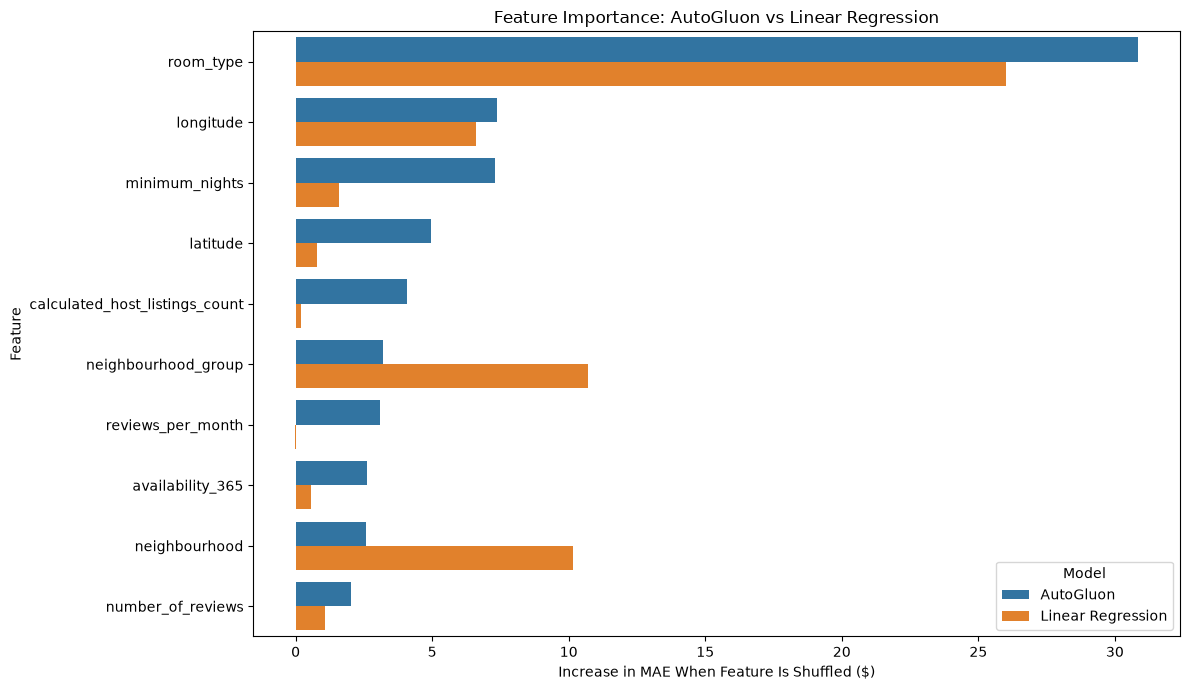

In [83]:
comparison_plot = feature_comparison.melt(
    id_vars="Feature",
    var_name="Model",
    value_name="Importance"
)

plt.figure(figsize=(12, 7))

sns.barplot(
    data=comparison_plot,
    x="Importance",
    y="Feature",
    hue="Model"
)

plt.title("Feature Importance: AutoGluon vs Linear Regression")
plt.xlabel("Increase in MAE When Feature Is Shuffled ($)")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

## Optional Task 2: Price Trend Visualizations

### Location Based

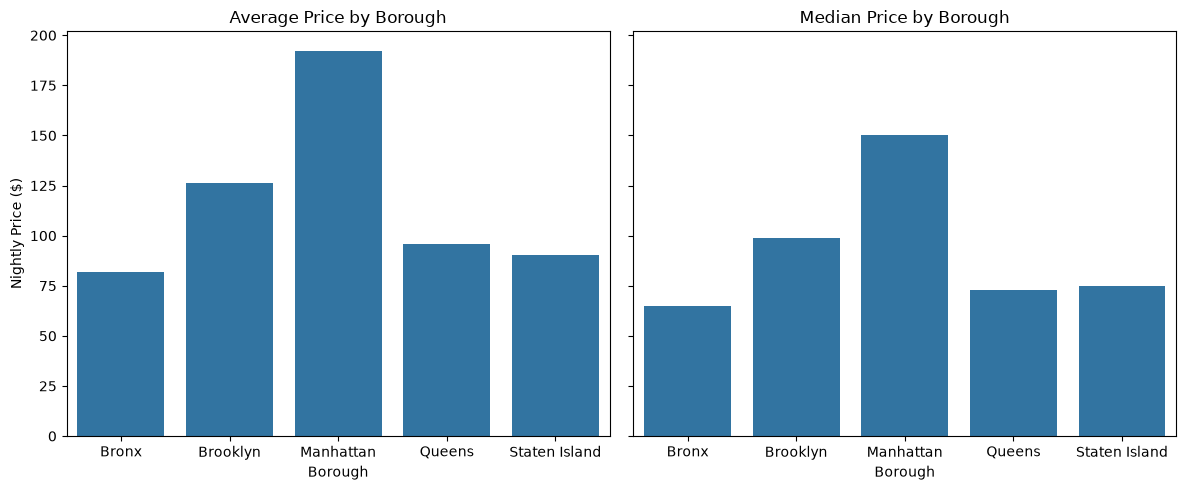

In [84]:
borough_mean_prices = df.groupby("neighbourhood_group")["price"].mean()
borough_median_prices = df.groupby("neighbourhood_group")["price"].median()

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)

# Average price
sns.barplot(x=borough_mean_prices.index, y=borough_mean_prices.values, ax=axes[0])
axes[0].set_title("Average Price by Borough")
axes[0].set_ylabel("Nightly Price ($)")
axes[0].set_xlabel("Borough")


# Median price
sns.barplot(x=borough_median_prices.index, y=borough_median_prices.values, ax=axes[1])
axes[1].set_title("Median Price by Borough")
axes[1].set_ylabel("")
axes[1].set_xlabel("Borough")


plt.tight_layout()
plt.show()

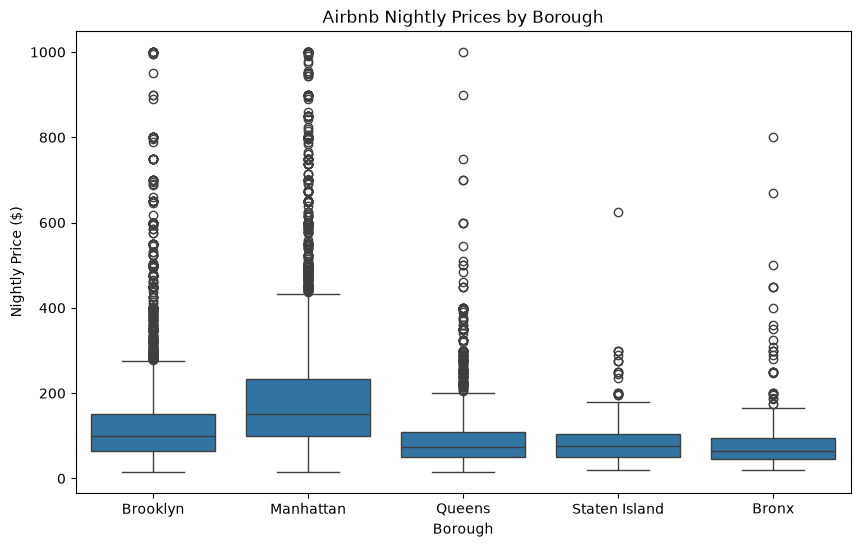

In [85]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="neighbourhood_group",
    y="price"
)

plt.title("Airbnb Nightly Prices by Borough")
plt.xlabel("Borough")
plt.ylabel("Nightly Price ($)")
plt.show()

#### Geographic Pricing Trends

Average and median nightly Airbnb prices were compared across New York City's five boroughs to examine how location influences pricing. Manhattan had the highest prices by a significant margin, with an average nightly price of approximately $192 and a median of $150. Brooklyn followed with an average of around $126 and a median of $99. Queens and Staten Island had lower average prices of approximately $96 and $90, respectively, while the Bronx had the lowest average at roughly $82.

The difference between mean and median prices was most noticeable in Manhattan, where the average was approximately $42 higher than the median. Brooklyn also showed a notable difference of around $27. This suggests that higher-priced listings pull the averages upward, particularly in Manhattan and Brooklyn. The results show that location plays an important role in Airbnb pricing, with Manhattan being considerably more expensive than the outer boroughs. The differences between mean and median prices also suggest that nightly prices are right-skewed, making the median a useful measure of a typical listing's cost.

### Property Type Based

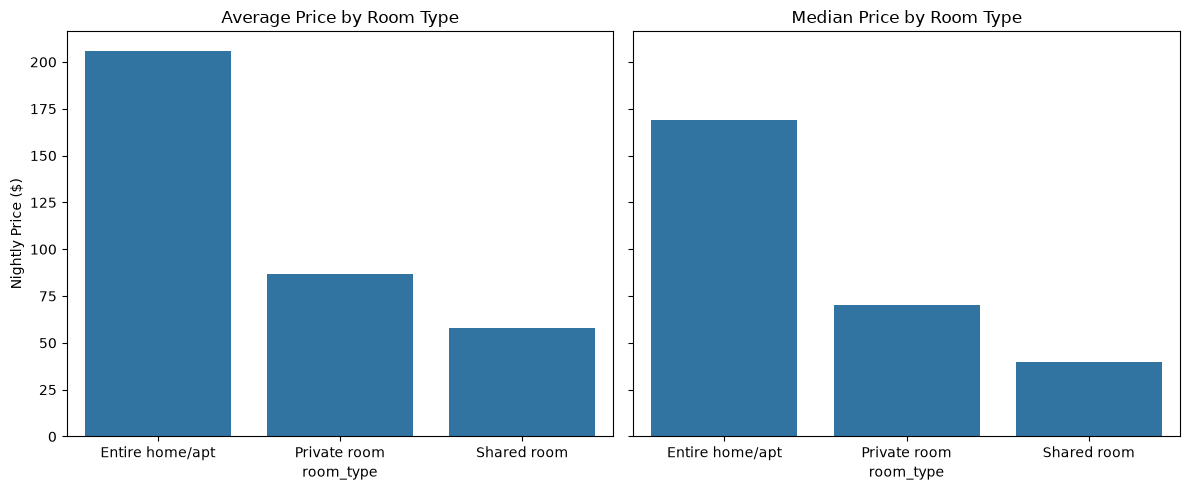

In [86]:
mean_prices = df.groupby("room_type")["price"].mean()
median_prices = df.groupby("room_type")["price"].median()

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)

# Average price
sns.barplot(x=mean_prices.index, y=mean_prices.values, ax=axes[0])
axes[0].set_title("Average Price by Room Type")
axes[0].set_ylabel("Nightly Price ($)")

# Median price
sns.barplot(x=median_prices.index, y=median_prices.values, ax=axes[1])
axes[1].set_title("Median Price by Room Type")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()

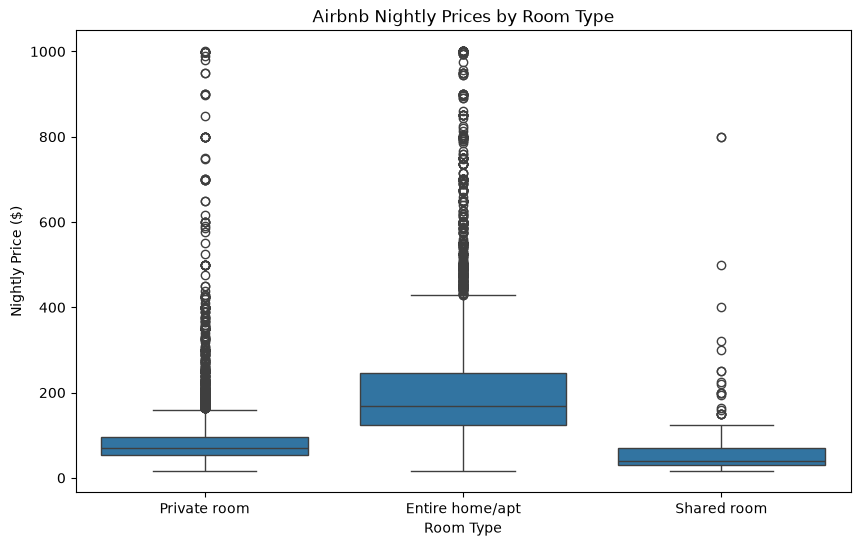

In [87]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="room_type",
    y="price"
)

plt.title("Airbnb Nightly Prices by Room Type")
plt.xlabel("Room Type")
plt.ylabel("Nightly Price ($)")
plt.show()

#### Pricing Trends by Property Type

Airbnb prices were also compared across entire homes, private rooms, and shared rooms. Entire homes generally had the highest nightly prices, followed by private rooms and shared rooms, as expected. The mean and median comparisons also highlight differences in price distributions within each category. Higher average prices relative to median prices suggest that expensive listings influence the overall average, particularly among entire homes. These findings help explain why room type was identified as the most important feature in the AutoGluon model.

### Amenity Based

In [94]:
Amenities = {
    "Pool": r"pool",
    "Hot tub": r"hot tub|jacuzzi",
    "Rooftop": r"rooftop",
    "Park": r"park",
    "Garden": r"garden",
    "Parking": r"parking|garage",
    "View": "skyline|city view",
    "Pet Friendly": r"pet",
    "Laundry": r"washer|dryer|laundry",
}

In [95]:
amenity_counts = pd.DataFrame({
    "Amenity": list(Amenities.keys()),
    "Count": [
        df["name"].fillna("").str.contains(
            rf"\b(?:{pattern})\b",
            case=False,
            regex=True
        ).sum()
        for pattern in Amenities.values()
    ]
})

display(amenity_counts.sort_values("Count", ascending=False))

,Amenity,Count
3,Park,1160
4,Garden,518
2,Rooftop,149
8,Laundry,131
5,Parking,116
6,View,57
0,Pool,37
1,Hot tub,13
7,Pet Friendly,5


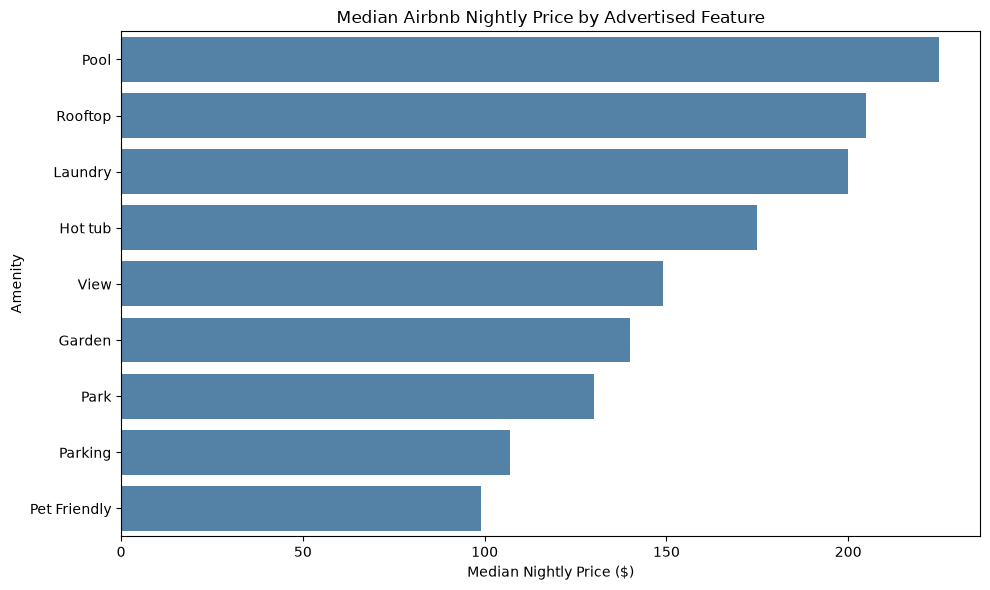

In [96]:
amenity_counts["Median Price"] = [
    df.loc[
        df["name"].fillna("").str.contains(
            rf"\b(?:{pattern})\b",
            case=False,
            regex=True
        ),
        "price"
    ].median()
    for pattern in Amenities.values()
]

amenity_plot = amenity_counts.sort_values(
    "Median Price", ascending=False
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=amenity_plot,
    x="Median Price",
    y="Amenity",
    color="steelblue"
)

plt.title("Median Airbnb Nightly Price by Advertised Feature")
plt.xlabel("Median Nightly Price ($)")
plt.ylabel("Amenity")

plt.tight_layout()
plt.show()

In [97]:
amenity_results = []

for amenity, pattern in Amenities.items():
    has_amenity = df["name"].fillna("").str.contains(
        rf"\b(?:{pattern})\b",
        case=False,
        regex=True
    )

    median_with = df.loc[has_amenity, "price"].median()
    median_without = df.loc[~has_amenity, "price"].median()

    amenity_results.append({
        "Amenity": amenity,
        "Count": has_amenity.sum(),
        "Median With": median_with,
        "Median Without": median_without,
        "Price Difference": median_with - median_without
    })

amenity_counts = pd.DataFrame(amenity_results)

display(amenity_counts)

,Amenity,Count,Median With,Median Without,Price Difference
0,Pool,37,225.0,109.0,116.0
1,Hot tub,13,175.0,109.0,66.0
2,Rooftop,149,205.0,108.0,97.0
3,Park,1160,130.0,105.0,25.0
4,Garden,518,140.0,105.0,35.0
5,Parking,116,107.0,109.0,-2.0
6,View,57,149.0,109.0,40.0
7,Pet Friendly,5,99.0,109.0,-10.0
8,Laundry,131,200.0,109.0,91.0


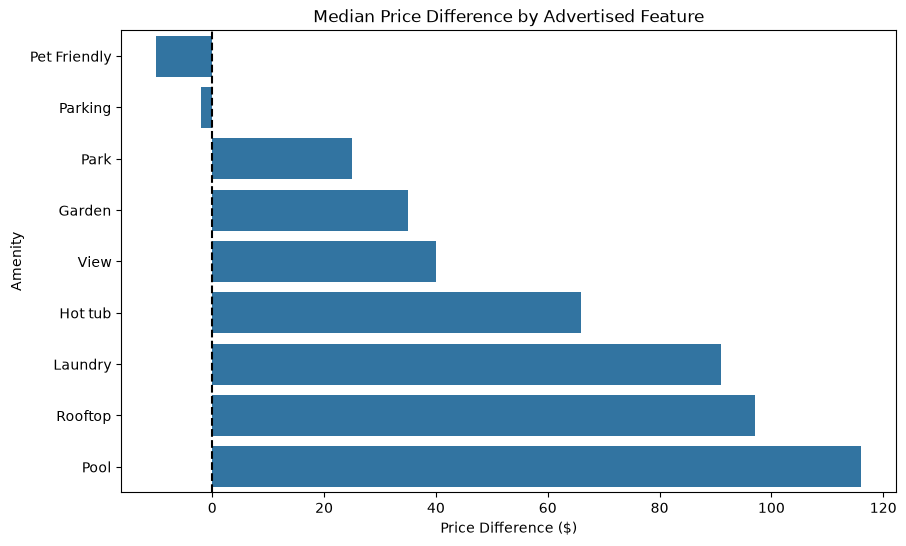

In [98]:
amenity_counts = amenity_counts.sort_values("Price Difference")

plt.figure(figsize=(10, 6))

sns.barplot(
    data=amenity_counts,
    x="Price Difference",
    y="Amenity"
)

plt.axvline(0, color="black", linestyle="--")
plt.title("Median Price Difference by Advertised Feature")
plt.xlabel("Price Difference ($)")
plt.ylabel("Amenity")
plt.show()

#### Advertised Amenities and Pricing

Since the NYC Airbnb dataset does not include a dedicated amenities column, keywords were extracted from listing names to investigate how advertised property features relate to nightly prices. Nine categories were examined, including pools, hot tubs, rooftops, gardens, parking, views, laundry, pet-friendly accommodations, and proximity to parks.

Listings mentioning pools had the largest positive median price difference, with a median nightly price of $225 compared to $109 for listings without a pool mention, a difference of $116. Rooftops also showed a substantial difference of $97, with a median price of $205 compared to $108 for other listings. Laundry-related features were associated with a $91 difference, while hot tubs and views showed differences of $66 and $40, respectively. Gardens and parks had smaller positive differences of $35 and $25, while parking showed almost no difference at −$2. However, sample sizes varied considerably across categories. Park mentions appeared in 1,160 listings and gardens in 518, while pools appeared in only 37 listings, hot tubs in 13, and pet-friendly keywords in just 5. The smaller sample sizes make some of the larger price differences less reliable and more sensitive to individual properties.

These results suggest that listings advertising features such as pools, rooftops, and laundry facilities tend to have higher median nightly prices. However, the analysis only identifies keywords mentioned in listing titles, not verified amenities. Also, differences in location, room type, and property characteristics may explain some of these pricing patterns.

## Write Up

### Limitations

Although the models demonstrated reasonable predictive performance, several limitations should be considered. First, the analysis uses the 2019 NYC Airbnb dataset, so the pricing patterns may not reflect current market conditions. The dataset also lacks detailed information about property size, number of bedrooms, verified amenities, and other characteristics that could help explain price differences.

Second, the preprocessing process excludes listings based on price, availability, and missing review information. These decisions reduce the number of observations and may introduce selection bias, limiting how well the results generalize to all Airbnb listings.

Also, the models were evaluated using a random train/test split. While this provides a useful estimate of performance on similar historical listings, it does not necessarily reflect accuracy for future listings or changing market conditions. Additional validation using newer data would help assess the models' reliability. 

### Conclusion

This project explored the use of AutoGluon to predict nightly Airbnb prices in New York City using property characteristics, location, review information, and listing descriptions. Multiple regression algorithms were trained and evaluated, including gradient-boosted trees, Random Forest, Extra Trees, and neural networks.

The original AutoGluon weighted ensemble achieved the best performance, with a test MAE of $42.70 and R² of 0.55. A controlled experiment was also conducted to compare AutoGluon and Linear Regression using the same input features. AutoGluon achieved an MAE of $46.28 compared with $57.60 for Linear Regression, reducing average absolute prediction error by approximately 19.7%.

Feature importance analysis identified room type as the strongest predictor for both modeling approaches. The original AutoGluon model also benefited from listing-name information, while the controlled comparison revealed differences in how the models used geographic and numerical features.

Exploratory analysis showed pricing differences across boroughs and property types, along with associations between advertised listing features and nightly prices. Entire homes generally had larger absolute prediction errors, although the relative errors were more comparable across property types.

The project demonstrates the usefulness of AutoML for tabular regression and highlights how feature selection, model complexity, and ensemble learning can influence predictive performance. Future improvements could include additional property details and evaluation on newer Airbnb listings.